In [ ]:
import tensorflow as tf
import tensorflow_hub as hub
import pandas as pd
import numpy as np
import os
import tf_keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from tf_keras import layers

In [28]:
#Load data
labels_csv = pd.read_csv("/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/dog-breed-identification/labels.csv")

filenames = [f"/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/dog-breed-identification/train/{fname}.jpg" for fname in labels_csv["id"]]

labels = np.array(labels_csv["breed"])

#One-Hot Encoding
unique_breeds = np.unique(labels)
boolean_labels = [label == unique_breeds for label in labels]

In [29]:
#Split data
NUM_IMAGES = 1000
x = filenames
y = boolean_labels
np.random.seed(555)
x_train, x_val, y_train, y_val = train_test_split(x,y)

In [30]:
#Create data pipeline
def preprocess_image(image_path, img_size=224):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.convert_image_dtype(image, tf.float32)
    image = tf.image.resize(image, size=[img_size, img_size])
    return image

def get_image_label(image_path, label):
    image = preprocess_image(image_path)
    return (image, label)


def create_data_batches(x, y=None, batch_size=32, valid_data=False, test_data=False):
    if(test_data):
        data = tf.data.Dataset.from_tensor_slices(tf.constant(x))
        data_batch = data.map(preprocess_image).batch(batch_size)
        return data_batch
    
    elif valid_data:
        data = tf.data.Dataset.from_tensor_slices((tf.constant(x), tf.constant(y)))
        data_batch = data.map(get_image_label).batch(batch_size)
        return data_batch
    else:
        data = tf.data.Dataset.from_tensor_slices((tf.constant(x), tf.constant(y)))
        data = data.shuffle(buffer_size=len(x))
        data_batch = data.map(get_image_label).batch(batch_size)
        return data_batch

In [31]:
#Create Model

INPUT_SHAPE = [None, 224, 224, 3]
OUTPUT_SHAPE = len(unique_breeds)
MODEL_URL = "https://tfhub.dev/google/imagenet/mobilenet_v2_130_224/classification/4"

def create_model(input_shape=INPUT_SHAPE, output_shape=OUTPUT_SHAPE, model_url=MODEL_URL):
    model = tf_keras.Sequential([hub.KerasLayer(model_url), layers.Dense(units=output_shape, activation="softmax")])
    model.compile(optimizer=tf_keras.optimizers.Adam(), loss="categorical_crossentropy", metrics=["accuracy"])
    model.build(input_shape)
    return model

In [32]:
model = create_model()

#Create data batches
print("Creating training data batches...")
train_data = create_data_batches(x_train, y_train)
print("Creating validation data batches...")
val_data = create_data_batches(x_val, y_val, valid_data=True)

#Train model
early_stopping = tf_keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3)
BATCH_SIZE=32
EPOCHS=20

zenitsu = model.fit(train_data, epochs=EPOCHS, batch_size=BATCH_SIZE, validation_data=val_data, callbacks=[early_stopping], steps_per_epoch=len(train_data), validation_steps=len(val_data))

Creating training data batches...
Creating validation data batches...
Epoch 1/20
240/240 [==============================] - 61s 252ms/step - loss: 1.5168 - accuracy: 0.6372 - val_loss: 0.7865 - val_accuracy: 0.7680
Epoch 2/20
240/240 [==============================] - 64s 268ms/step - loss: 0.3991 - accuracy: 0.8856 - val_loss: 0.7187 - val_accuracy: 0.7958
Epoch 3/20
240/240 [==============================] - 69s 287ms/step - loss: 0.2264 - accuracy: 0.9438 - val_loss: 0.7301 - val_accuracy: 0.7926
Epoch 4/20
240/240 [==============================] - 71s 298ms/step - loss: 0.1405 - accuracy: 0.9701 - val_loss: 0.7271 - val_accuracy: 0.7997
Epoch 5/20
240/240 [==============================] - 71s 296ms/step - loss: 0.0957 - accuracy: 0.9838 - val_loss: 0.7333 - val_accuracy: 0.7989
Epoch 6/20
240/240 [==============================] - 69s 290ms/step - loss: 0.0681 - accuracy: 0.9917 - val_loss: 0.7428 - val_accuracy: 0.8013
Epoch 7/20
240/240 [==============================] - 71s 29

In [33]:
print("Evaluating Model...")
val_loss, val_acc = model.evaluate(val_data)
print(f"Validation Accuracy: {val_acc*100:.2f}")
print(f"Validation Loss: {val_loss:.4f}")

Evaluating Model...
80/80 [==============================] - 15s 180ms/step - loss: 0.8133 - accuracy: 0.7993
Validation Accuracy: 79.93
Validation Loss: 0.8133


In [ ]:
def get_pred_label(prediction_probabilities):
  return unique_breeds[np.argmax(prediction_probabilities)]

custom_path = "/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/Dog Photos/"
custom_image_paths = [custom_path + fname for fname in os.listdir(custom_path)]

#Preprocessing images
custom_data = create_data_batches(custom_image_paths, test_data=True)

#Make predictions
custom_preds = model.predict(custom_data)

custom_pred_labels = [get_pred_label(preds) for preds in custom_preds]

custom_images= []

for image in custom_data.unbatch().as_numpy_iterator():
  custom_images.append(image)



1/1 [==============================] - 0s 170ms/step


2025-05-28 16:17:28.045524: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


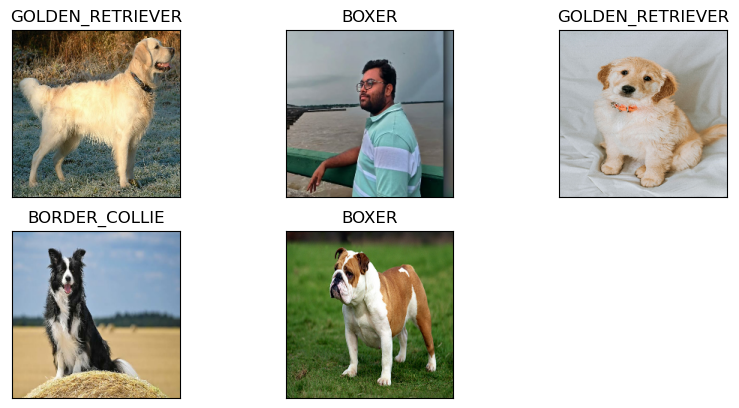

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,10))

for i, image in enumerate(custom_images):
    plt.subplot(4,3,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.title(custom_pred_labels[i].upper())
    plt.imshow(image)